# SD-008 Fraud Analytics EDA

This notebook uses only analyst-facing exports. It never reads simulator latent states or row-level ground truth. Set `DATA_DIR` to a newly generated D2 run directory.

In [1]:
from pathlib import Path
import json
import os
import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path(os.environ.get('DATA_DIR', '../D2_Synthetic_Dataset_Generator/outputs/run_20261101_REPLACE_ME'))
if not (DATA_DIR / 'manifest.json').is_file():
    runs = sorted(DATA_DIR.glob('run_*')) if DATA_DIR.is_dir() else []
    if len(runs) != 1:
        raise FileNotFoundError('Set DATA_DIR to a run_* directory or a directory containing exactly one run_*.')
    DATA_DIR = runs[0]
manifest = json.loads((DATA_DIR / 'manifest.json').read_text())
tables = {name[:-4]: pd.read_csv(DATA_DIR / name) for name in manifest['columns'] if name.endswith('.csv') and name != 'label_gap_summary.csv'}
cardholders, cards, merchants, tx, labels = (tables[k] for k in ['cardholders', 'cards', 'merchants', 'transactions', 'fraud_labels'])
tx['transaction_ts'] = pd.to_datetime(tx['transaction_ts'])
for c in ['alert_ts', 'review_ts']:
    labels[c] = pd.to_datetime(labels[c])
print({name: len(frame) for name, frame in tables.items()})

{'cardholders': 2000, 'cards': 2613, 'fraud_labels': 1567, 'merchants': 500, 'transactions': 150000}


## Executive overview

**Question:** What can an analyst infer from sparse review outcomes? **Method:** descriptive denominators use all transactions for coverage and only resolved investigated records for observed-label rates. **Limitation:** uninvestigated records are unknown, not confirmed legitimate.

Label-row coverage: 1.04%; resolved observed-positive rate: 7.72%.
Interpretation: the latter is selected-review evidence, not a population fraud estimate.


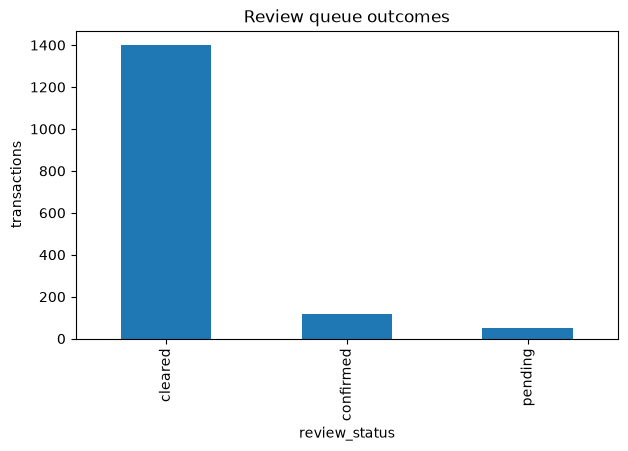

In [2]:
resolved = labels[labels['observed_fraud'].notna()].copy()
coverage = len(labels) / len(tx)
resolved_rate = resolved['observed_fraud'].astype(bool).mean()
print(f'Label-row coverage: {coverage:.2%}; resolved observed-positive rate: {resolved_rate:.2%}.')
print('Interpretation: the latter is selected-review evidence, not a population fraud estimate.')
fig, ax = plt.subplots(figsize=(7,4)); labels['review_status'].value_counts().plot.bar(ax=ax, title='Review queue outcomes'); ax.set_ylabel('transactions'); plt.show()

## Amounts, activity, merchants, geography, and velocity

**Question:** Where are normal behavioral ranges and operational concentrations? **Method:** distributions and grouped counts; these are associations, not causal proof.

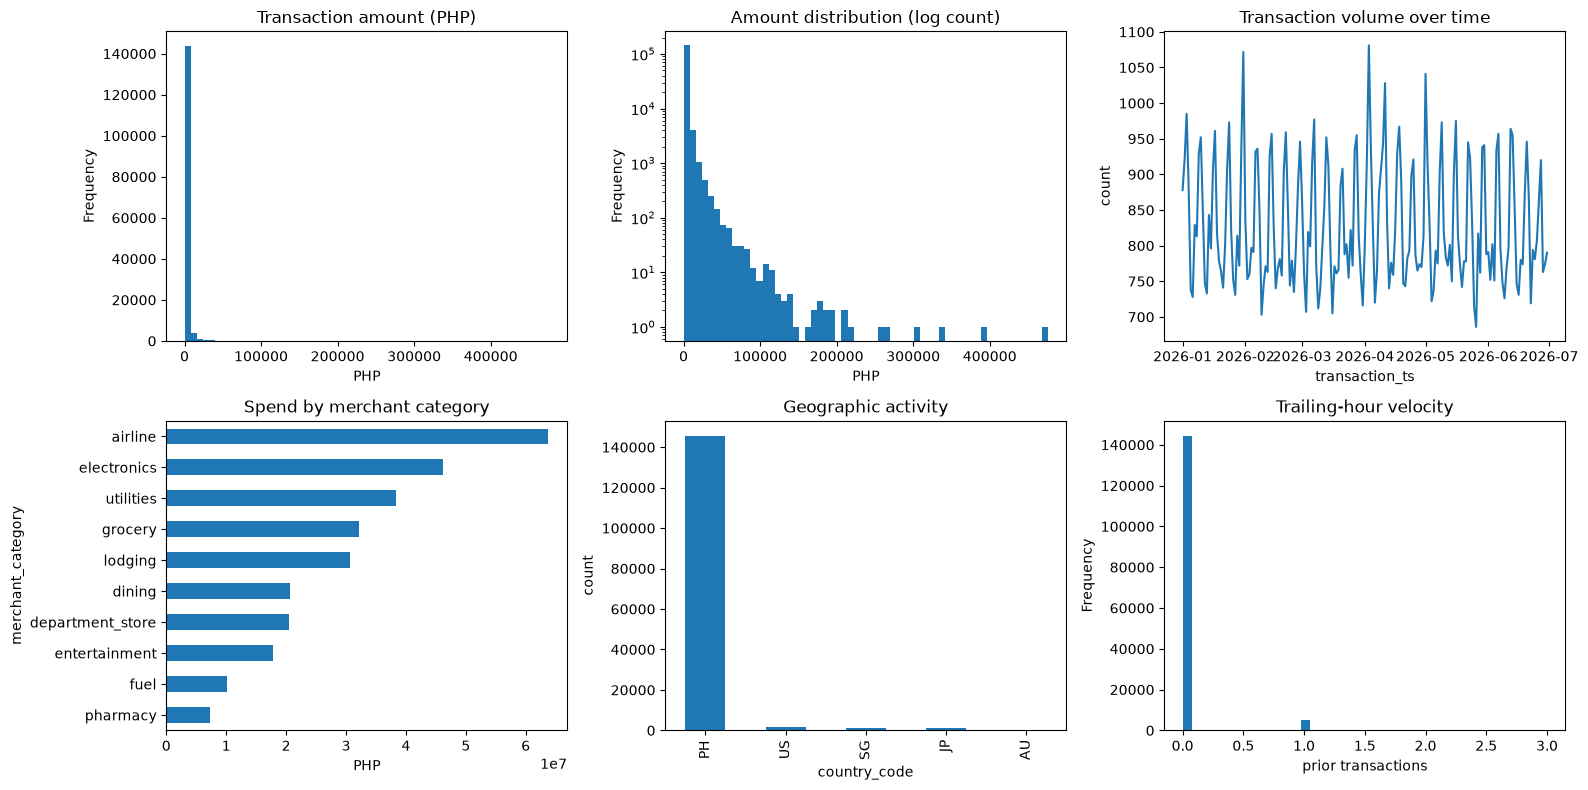

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16,8))
tx['amount_php'].plot.hist(bins=60, ax=axes[0,0], title='Transaction amount (PHP)'); axes[0,0].set_xlabel('PHP')
tx['amount_php'].plot.hist(bins=60, logy=True, ax=axes[0,1], title='Amount distribution (log count)'); axes[0,1].set_xlabel('PHP')
tx.groupby(tx['transaction_ts'].dt.date).size().plot(ax=axes[0,2], title='Transaction volume over time'); axes[0,2].set_ylabel('count')
tx.merge(merchants[['merchant_id','merchant_category']], on='merchant_id').groupby('merchant_category')['amount_php'].sum().sort_values().plot.barh(ax=axes[1,0], title='Spend by merchant category'); axes[1,0].set_xlabel('PHP')
tx.merge(merchants[['merchant_id','country_code']], on='merchant_id')['country_code'].value_counts().plot.bar(ax=axes[1,1], title='Geographic activity'); axes[1,1].set_ylabel('count')
tx['tx_count_prev_1h'].plot.hist(bins=40, ax=axes[1,2], title='Trailing-hour velocity'); axes[1,2].set_xlabel('prior transactions')
plt.tight_layout(); plt.show()

## Data quality and observed-fraud comparison

**Question:** Are missing values expected, and how do observable features overlap among resolved outcomes? **Method:** display missingness and restrict outcome comparisons to resolved labels. High values and velocity are signals, not proof.

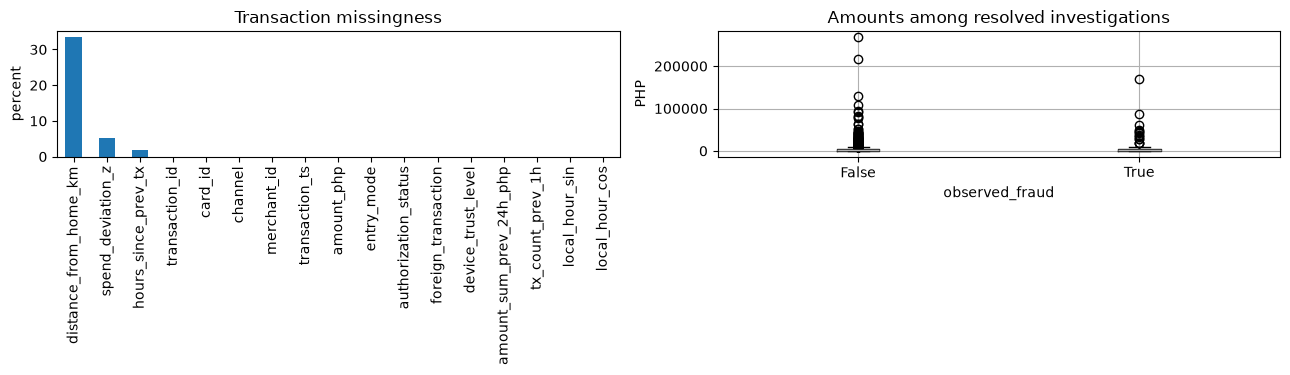

Analyst implication: retain a review queue; do not label unreviewed events as legitimate for model training.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13,4))
(tx.isna().mean().sort_values(ascending=False)*100).plot.bar(ax=axes[0], title='Transaction missingness'); axes[0].set_ylabel('percent')
case = tx.merge(resolved[['transaction_id','observed_fraud']], on='transaction_id', how='inner')
case.boxplot(column='amount_php', by='observed_fraud', ax=axes[1]); axes[1].set_title('Amounts among resolved investigations'); axes[1].set_ylabel('PHP'); plt.suptitle('')
plt.tight_layout(); plt.show()
print('Analyst implication: retain a review queue; do not label unreviewed events as legitimate for model training.')

## Recommendations and limitations

- Prioritize alerts with velocity, unfamiliar-device, geography, and amount context jointly; no single observable is proof.
- Monitor review capacity because observed labels reflect selection into investigation.
- Treat any workload or cost exercise as hypothetical until calibrated against operational evidence.
- This synthetic scenario is not externally validated against production Philippine card transactions.